# Les bases de LangChain : du LLM à l'agent

Cours de référence : chaque section introduit **un** concept, avec du code court et exécutable.
Les sections s'appuient les unes sur les autres. Lis-les dans l'ordre la première fois, puis sers-toi de la table des matières comme aide-mémoire.

| # | Section | Idée clé |
|---|---|---|
| 0 | Installation | `uv sync`, `.env`, choix du modèle |
| 1 | Ce qu'est un LLM | tokens, **aucune mémoire**, température |
| 2 | Créer un LLM | `ChatOpenAI`, `init_chat_model` |
| 3 | Les messages | 4 types, 4 formats, `AIMessage` en détail |
| 4 | Appeler le modèle | `invoke`, `stream`, `batch`, `ainvoke` |
| 5 | Prompt templates & chaînes | `ChatPromptTemplate`, opérateur `\|` (LCEL) |
| 6 | Sortie structurée | `with_structured_output(Pydantic)` |
| 7 | Multimodal | vision (image en entrée) + génération d'image |
| 8 | Outils & boucle agent | `@tool`, `bind_tools`, `ToolMessage`, la boucle à la main |
| 9 | `create_agent` | l'agent « tout fait » de LangChain 1.x |
| 10 | Mémoire | court terme (checkpointer) et long terme (store) |
| 11 | Middleware | intercepter l'agent : avant/après le modèle, autour des outils |
| 12 | Human-in-the-loop | `HumanInTheLoopMiddleware`, `interrupt()`, `Command(resume=…)` |
| 13 | MCP | serveur FastMCP, monté dans FastAPI, client LangChain |
| 14 | RAG minimal | découpage, embeddings, vector store, outil de recherche |
| 15 | LangGraph | la même boucle agent, en graphe explicite |
| 16 | Production | coût en tokens, retries, fallbacks, traçage LangSmith |
| 17 | Aide-mémoire | les imports et les signatures à connaître |

## 0. Installation

```bash
uv sync                      # installe l'environnement depuis pyproject.toml / uv.lock
copy .env.example .env       # puis renseigner OPENAI_API_KEY
```

Dans VS Code, choisis le kernel `.venv` du projet. Les sections 13 (MCP) lancent elles-mêmes les serveurs `serveur_mcp.py` et `serveur_fastapi.py`.

In [1]:
from dotenv import load_dotenv
from IPython.display import Image, Markdown, display

load_dotenv(override=True)   # lit OPENAI_API_KEY depuis .env

MODELE = "gpt-4.1-mini"       # rapide et peu cher, accepte texte + images
MODELE_IMAGE = "gpt-5.2"      # sait appeler l'outil intégré de génération d'image

## 1. Ce qu'est un LLM : trois idées avant toute syntaxe

1. **Un LLM lit et produit des tokens**, des morceaux de mots. On paie, et on est limité (fenêtre de contexte), en tokens.
2. **Un LLM n'a aucune mémoire.** Chaque appel est indépendant : la « conversation », c'est **toi** qui la renvoies à chaque fois.
3. **Un LLM ne fait que produire du texte.** Quand il « appelle un outil », il écrit seulement une *demande* d'appel : c'est ton code qui l'exécute (section 8).

In [2]:
import tiktoken

encodage = tiktoken.get_encoding("o200k_base")   # l'encodeur des modèles GPT-4o / 4.1 / 5
texte = "Un agent IA appelle des outils."
ids = encodage.encode(texte)

print(f"{len(ids)} tokens : {ids}")
print("|".join(encodage.decode([i]) for i in ids))

7 tokens : [2265, 11793, 59199, 111796, 731, 63365, 13]
Un| agent| IA| appelle| des| outils|.


## 2. Créer (initialiser) un LLM

Deux façons de faire, avec le même résultat :

- **La classe du fournisseur** (`ChatOpenAI`, `ChatAnthropic`, `ChatOllama`…) : accès à tous les paramètres propres à ce fournisseur.
- **`init_chat_model("fournisseur:modele")`** : une seule fonction quel que soit le fournisseur. On change de modèle en changeant une chaîne de caractères.

| Paramètre | Rôle |
|---|---|
| `temperature` | 0 = déterministe, plus haut = plus créatif (les modèles de raisonnement gpt-5 ne l'acceptent pas) |
| `max_tokens` | longueur maximale de la **réponse** |
| `timeout`, `max_retries` | robustesse réseau |

In [2]:
from langchain_openai import ChatOpenAI
from langchain.chat_models import init_chat_model

llm = ChatOpenAI(model=MODELE, temperature=0, max_tokens=800, timeout=60, max_retries=2)

llm_generique = init_chat_model(f"openai:{MODELE}", temperature=0)

print(type(llm).__name__, "|", type(llm_generique).__name__)

ChatOpenAI | ChatOpenAI


Preuve de l'idée n°2 : **deux appels séparés ne partagent rien**.

In [3]:
llm.invoke("Bonjour, je m'appelle Hamza.")
reponse = llm.invoke("Comment je m'appelle ?")
print(reponse.content)

Je ne connais pas ton prénom, pourrais-tu me le dire ?


## 3. Les messages

### 3.1 Les quatre types

| Classe | `role` (format dict) | Contenu | Qui le crée |
|---|---|---|---|
| `SystemMessage` | `system` | consignes, persona, règles | toi |
| `HumanMessage` | `user` | la demande de l'utilisateur (texte, images…) | toi |
| `AIMessage` | `assistant` | réponse du modèle : `.content` **et/ou** `.tool_calls` | le LLM |
| `ToolMessage` | `tool` | résultat d'un outil, relié par `tool_call_id` | toi, après exécution |

### 3.2 Les quatre formats acceptés par `invoke`
LangChain convertit tout vers des objets messages. Ces quatre appels envoient donc **la même chose** au modèle.

In [5]:
from langchain.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage

# a) une simple chaîne de caractères -> un HumanMessage
r_a = llm.invoke("Écris un haïku sur le printemps.")

# b) des tuples (role, contenu)
r_b = llm.invoke([
    ("system", "Tu es un expert en poésie japonaise."),
    ("user", "Écris un haïku sur le printemps."),
])

# c) des dictionnaires : le format de l'API OpenAI
r_c = llm.invoke([
    {"role": "system", "content": "Tu es un expert en poésie japonaise."},
    {"role": "user", "content": "Écris un haïku sur le printemps."},
])

# d) des objets messages : le plus explicite, recommandé dans du vrai code
r_d = llm.invoke([
    SystemMessage("Tu es un expert en poésie japonaise."),
    HumanMessage("Écris un haïku sur le printemps."),
])

print(r_d.content)

Fleurs épanouies,  
souffle doux du vent léger,  
printemps s’éveille.


### 3.3 La mémoire, c'est la liste de messages
Pour qu'un modèle « se souvienne », on lui renvoie l'historique, y compris ses propres réponses (`AIMessage`).

In [6]:
historique = [
    SystemMessage("Tu es un assistant concis."),
    HumanMessage("Bonjour, je m'appelle Hamza."),
]
historique.append(llm.invoke(historique))           # on garde la réponse du modèle
historique.append(HumanMessage("Comment je m'appelle ?"))
print(llm.invoke(historique).content)

Vous vous appelez Hamza.


### 3.4 Few-shot : des `AIMessage` écrits à la main
On peut **fabriquer** de faux échanges pour montrer au modèle le format attendu. C'est souvent plus efficace que de le décrire.

In [7]:
few_shot = [
    SystemMessage("Classe le sentiment d'un avis client. Réponds par un seul mot."),
    HumanMessage("Livraison rapide, produit parfait."), AIMessage("POSITIF"),
    HumanMessage("Colis abîmé et service client absent."), AIMessage("NÉGATIF"),
    HumanMessage("Reçu le produit, conforme à la description."),
]
print(llm.invoke(few_shot).content)

POSITIF


### 3.5 Anatomie d'un `AIMessage`

In [8]:
print("content          :", r_d.content[:60], "…")
print("id               :", r_d.id)
print("usage_metadata   :", r_d.usage_metadata)        # tokens entrée / sortie : le coût
print("modèle utilisé   :", r_d.response_metadata.get("model_name"))
print("fin de génération:", r_d.response_metadata.get("finish_reason"))
print("tool_calls       :", r_d.tool_calls)            # vide ici : aucun outil fourni
print("content_blocks   :", r_d.content_blocks)        # format standard, identique quel que soit le fournisseur
r_d.pretty_print()

content          : Fleurs épanouies,  
souffle doux du vent léger,  
printemps  …
id               : lc_run--01a1a658-e59b-73c2-9adc-95300c4d4e1f-0
usage_metadata   : {'input_tokens': 30, 'output_tokens': 23, 'total_tokens': 53, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}
modèle utilisé   : gpt-4.1-mini-2025-04-14
fin de génération: stop
tool_calls       : []
content_blocks   : [{'type': 'text', 'text': 'Fleurs épanouies,  \nsouffle doux du vent léger,  \nprintemps s’éveille.'}]
================================== Ai Message ==================================

Fleurs épanouies,  
souffle doux du vent léger,  
printemps s’éveille.


## 4. Appeler le modèle : `invoke`, `stream`, `batch`, `ainvoke`

Tout objet LangChain (LLM, prompt, chaîne, agent) est un **Runnable** et possède ces mêmes méthodes.

| Méthode | Usage |
|---|---|
| `invoke(x)` | un appel, on attend la réponse complète |
| `stream(x)` | la réponse arrive morceau par morceau (`AIMessageChunk`) : indispensable pour une interface de chat |
| `batch([x1, x2])` | plusieurs appels **en parallèle** |
| `ainvoke` / `astream` / `abatch` | versions `async` (serveurs web, FastAPI, MCP) |

In [9]:
morceaux = None
for morceau in llm.stream("Explique ce qu'est un token dans un LLM, en deux phrases."):
    print(morceau.content, end="", flush=True)
    morceaux = morceau if morceaux is None else morceaux + morceau   # les chunks s'additionnent
print("\n\nMessage reconstitué :", type(morceaux).__name__, len(morceaux.content), "caractères")

Un

 token

 dans

 un

 L

LM

... (56 outputs left out)

quent

ielle

.



Message reconstitué : AIMessageChunk 292 caractères


In [10]:
reponses = llm.batch(["Capitale du Maroc ?", "Capitale du Japon ?", "Capitale du Canada ?"])
for r in reponses:
    print(r.content)

La capitale du Maroc est Rabat.
La capitale du Japon est Tokyo.
La capitale du Canada est Ottawa.


In [11]:
# Dans un notebook, `await` fonctionne directement au niveau de la cellule.
reponse = await llm.ainvoke("Donne un synonyme de 'rapide'.")
print(reponse.content)

Un synonyme de "rapide" est "vite".


## 5. Prompt templates et chaînes (LCEL)

- Un **`ChatPromptTemplate`** est une liste de messages à trous `{variable}`.
- **`MessagesPlaceholder`** réserve la place d'une liste de messages entière, typiquement l'historique.
- L'opérateur **`|`** enchaîne des Runnables : la sortie de l'un devient l'entrée du suivant (LCEL, *LangChain Expression Language*).

In [ ]:
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

prompt = ChatPromptTemplate.from_messages([
    ("system", "Tu es un traducteur professionnel vers le {langue}. Réponds uniquement par la traduction."),
    ("human", "{texte}"),
])

# Ce que le template produit, avant tout appel au modèle :
print(prompt.invoke({"langue": "anglais", "texte": "Bonjour"}).to_messages())

chaine = prompt | llm | StrOutputParser()      # dict -> messages -> AIMessage -> str
print(chaine.invoke({"langue": "anglais", "texte": "Le devis est prêt, merci de le valider."}))

[SystemMessage(content='Tu es un traducteur professionnel vers le anglais. Réponds uniquement par la traduction.', additional_kwargs={}, response_metadata={}), HumanMessage(content='Bonjour', additional_kwargs={}, response_metadata={})]


The quote is ready, please approve it.


In [13]:
prompt_chat = ChatPromptTemplate.from_messages([
    ("system", "Tu es un assistant commercial."),
    MessagesPlaceholder("historique"),
    ("human", "{question}"),
])
chaine_chat = prompt_chat | llm | StrOutputParser()

print(chaine_chat.invoke({
    "historique": [HumanMessage("Je cherche des ballons."), AIMessage("Combien vous en faut-il ?")],
    "question": "Une vingtaine. Tu peux me rappeler ce que je cherche ?",
}))

Vous cherchez une vingtaine de ballons. Souhaitez-vous des ballons de fête, des ballons de sport, ou un autre type de ballons ?


## 6. Sortie structurée

Au lieu de texte libre à analyser, on demande au modèle de remplir un **schéma Pydantic**.
Les descriptions des champs font partie du prompt : soigne-les.

In [ ]:
from pydantic import BaseModel, Field

class Ligne(BaseModel):
    article: str = Field(description="Nom de l'article")
    quantite: int = Field(description="Quantité demandée")

class Commande(BaseModel):
    client: str = Field(description="Nom du client")
    ville: str | None = Field(default=None, description="Ville du client si elle est mentionnée")
    lignes: list[Ligne]

extracteur = llm.with_structured_output(Commande)
commande = extracteur.invoke(
    "Bonjour, ici Sport Plus à Casablanca. Il nous faudrait 20 ballons et 5 gourdes svp."
)
print(type(commande).__name__)
print(commande.model_dump_json(indent=2))

Commande
{
  "client": "Sport Plus",
  "ville": "Casablanca",
  "lignes": [
    {
      "article": "ballons",
      "quantite": 20
    },
    {
      "article": "gourdes",
      "quantite": 5
    }
  ]
}


## 7. Multimodal : générer puis regarder une image

### 7.1 Génération d'image
Chez OpenAI, la génération d'image est un **outil intégré** (`image_generation`) que le modèle appelle côté serveur.
L'image revient en base64 dans les `content_blocks` de la réponse.

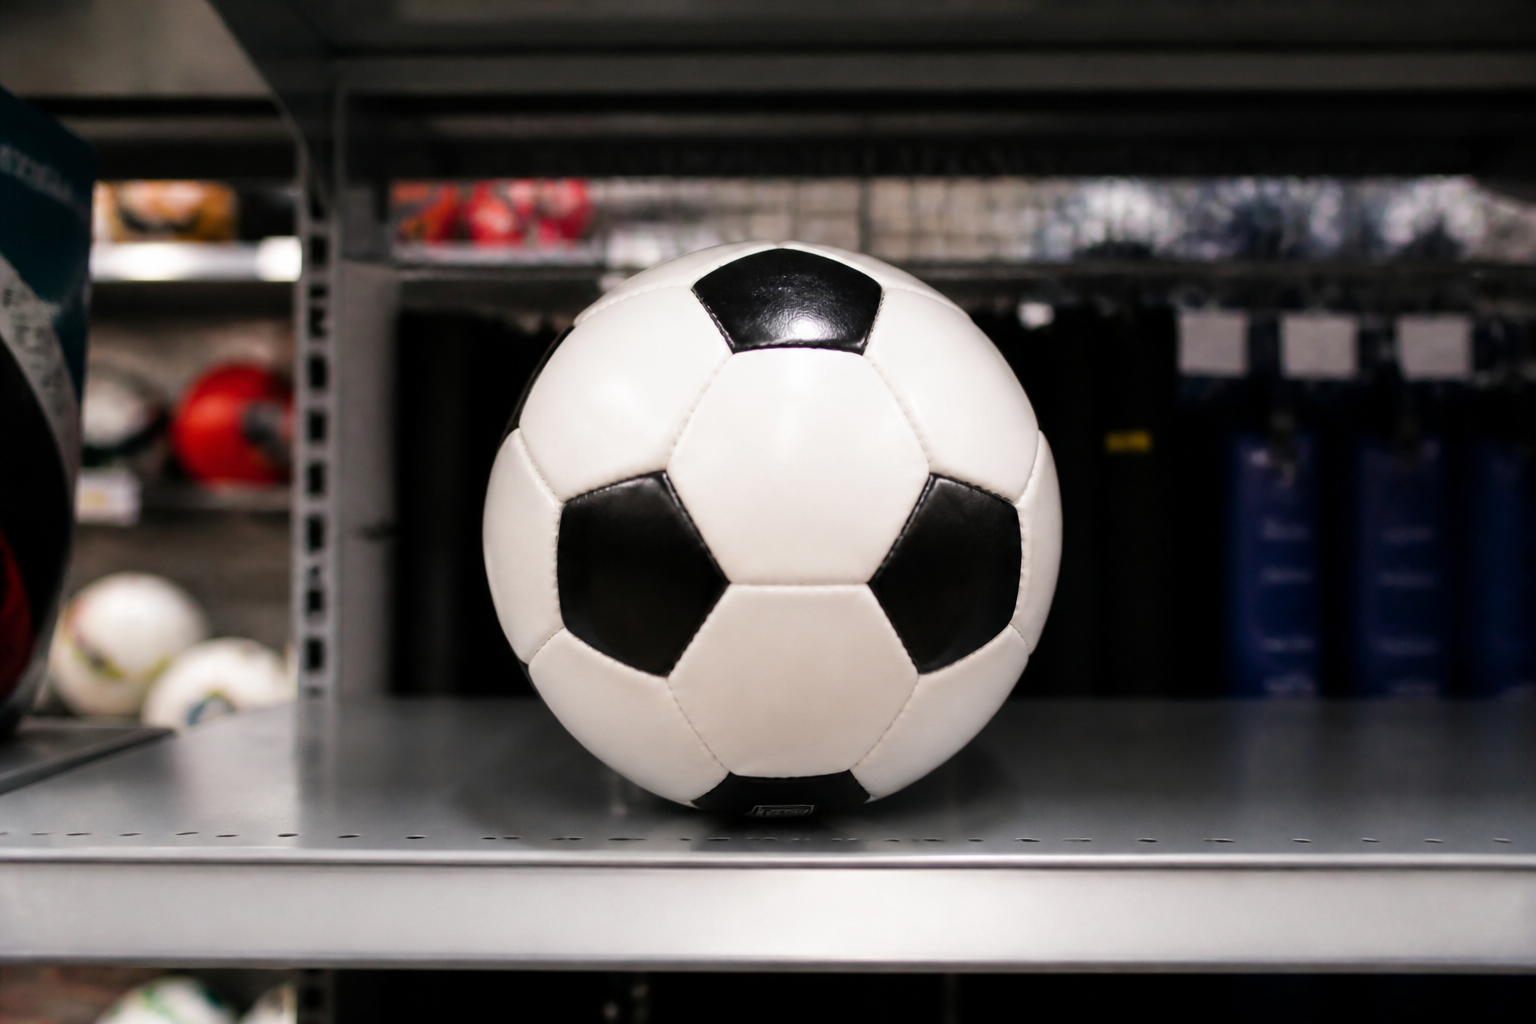

In [15]:
import base64
from pathlib import Path

llm_image = ChatOpenAI(model=MODELE_IMAGE).bind_tools([{"type": "image_generation", "quality": "low"}])
reponse_image = llm_image.invoke("Génère une image d'un ballon de football posé sur une étagère de magasin.")

bloc_image = next(b for b in reponse_image.content_blocks if b["type"] == "image")
chemin_image = Path("images/ballon.png")
chemin_image.write_bytes(base64.b64decode(bloc_image["base64"]))
display(Image(str(chemin_image), width=350))

### 7.2 Vision : une image en entrée
Un `HumanMessage` peut contenir **une liste de blocs** (texte, image, fichier, audio). Deux syntaxes possibles :
- le format **standard LangChain** `{"type": "image", "base64": …, "mime_type": …}`, portable d'un fournisseur à l'autre ;
- le format **OpenAI** `{"type": "image_url", "image_url": {"url": "data:…"}}`, comme dans le TP1.

In [16]:
image_b64 = base64.b64encode(chemin_image.read_bytes()).decode()

message_vision = HumanMessage(content=[
    {"type": "text", "text": "Décris cette image en une phrase, puis liste les objets visibles."},
    {"type": "image", "base64": image_b64, "mime_type": "image/png"},
])
display(Markdown(llm.invoke([message_vision]).content))

Cette image montre un ballon de football noir et blanc posé sur une étagère métallique dans un magasin.

Objets visibles :
- Ballon de football noir et blanc
- Étagère métallique
- Autres ballons flous en arrière-plan (rouge, blanc)
- Vêtements ou sacs suspendus en arrière-plan (flous)

## 8. Les outils et la boucle agent

Un **outil**, c'est une fonction Python et sa **description** (nom, docstring, types des paramètres).
Le LLM ne voit **que la description**. Il décide d'appeler l'outil et écrit les arguments ; c'est ton code qui l'exécute.

In [17]:
from langchain.tools import tool

STOCK = {"BALLON01": 42, "MAILLOT02": 0, "GOURDE03": 7}
PRIX = {"BALLON01": 19.9, "MAILLOT02": 35.0, "GOURDE03": 8.5}

@tool
def consulter_stock(reference: str) -> int:
    """Renvoie la quantité en stock d'un article à partir de sa référence (ex. BALLON01)."""
    if reference not in STOCK:
        raise ValueError(f"Référence inconnue : {reference}")
    return STOCK[reference]

@tool
def calculer_devis(reference: str, quantite: int) -> dict:
    """Calcule le montant HT d'un devis pour un article et une quantité."""
    return {"reference": reference, "quantite": quantite, "total_ht": round(PRIX[reference] * quantite, 2)}

outils = [consulter_stock, calculer_devis]

# Ce que le LLM « voit » de l'outil :
print(consulter_stock.name, "|", consulter_stock.description)
print(consulter_stock.args)
# Un outil est aussi un Runnable : on peut l'appeler soi-même.
print(consulter_stock.invoke({"reference": "GOURDE03"}))

consulter_stock | Renvoie la quantité en stock d'un article à partir de sa référence (ex. BALLON01).
{'reference': {'title': 'Reference', 'type': 'string'}}
7


### 8.1 `bind_tools` : le LLM connaît les outils mais ne les exécute pas

In [18]:
llm_outils = llm.bind_tools(outils)

ia = llm_outils.invoke("Combien de BALLON01 en stock, et combien coûteraient 10 gourdes GOURDE03 ?")
print("content    :", repr(ia.content))      # souvent vide : le modèle a préféré demander des outils
for appel in ia.tool_calls:
    print("tool_call  :", appel)              # {'name', 'args', 'id', 'type'}

content    : ''
tool_call  : {'name': 'consulter_stock', 'args': {'reference': 'BALLON01'}, 'id': 'call_F2aRpulmofeUYIyIRHRuUfDS', 'type': 'tool_call'}
tool_call  : {'name': 'calculer_devis', 'args': {'reference': 'GOURDE03', 'quantite': 10}, 'id': 'call_4S7vJsh7u2GtdjtM2qBS1rNX', 'type': 'tool_call'}


### 8.2 La boucle agent, écrite à la main

**C'est le concept le plus important du notebook.** Tout le reste (`create_agent`, LangGraph) automatise cette boucle :

```
LLM ──tool_calls?──► non ─► réponse finale
 ▲          │ oui
 │          ▼
 └── ToolMessage(résultat, tool_call_id) ◄── ton code exécute l'outil
```

In [19]:
outils_par_nom = {o.name: o for o in outils}

def boucle_agent(question: str, max_tours: int = 5) -> str:
    messages = [SystemMessage("Tu es un assistant de vente. Utilise les outils."), HumanMessage(question)]
    for tour in range(max_tours):                       # garde-fou : jamais de boucle infinie
        ia = llm_outils.invoke(messages)
        messages.append(ia)
        if not ia.tool_calls:                            # plus de demande d'outil -> réponse finale
            return ia.content
        for appel in ia.tool_calls:                      # le modèle peut en demander plusieurs à la fois
            print(f"  tour {tour} -> {appel['name']}({appel['args']})")
            try:
                resultat = outils_par_nom[appel["name"]].invoke(appel["args"])
            except Exception as e:                       # une erreur est un résultat comme un autre :
                resultat = f"Erreur : {e}"               # le modèle peut la lire et se corriger
            messages.append(ToolMessage(str(resultat), tool_call_id=appel["id"]))
    return "Arrêt : trop de tours."

print(boucle_agent("Combien de BALLON01 en stock, et combien coûteraient 10 gourdes GOURDE03 ?"))

  tour 0 -> consulter_stock({'reference': 'BALLON01'})
  tour 0 -> calculer_devis({'reference': 'GOURDE03', 'quantite': 10})


Il y a 42 BALLON01 en stock. Le coût pour 10 gourdes GOURDE03 serait de 85,00 € HT. Souhaitez-vous passer commande ou avez-vous besoin d'autres informations ?


## 9. `create_agent` : l'agent de LangChain 1.x

`create_agent` construit **exactement la boucle ci-dessus**, sous forme de graphe LangGraph, avec en plus la mémoire, le streaming, les middlewares et les interruptions.
Depuis LangChain 1.0, il remplace `create_react_agent` (LangGraph) et les anciens `AgentExecutor`.

| Paramètre | Rôle |
|---|---|
| `model` | un LLM, ou une chaîne `"openai:gpt-4.1-mini"` |
| `tools` | liste d'outils |
| `system_prompt` | consignes |
| `response_format` | schéma Pydantic : réponse finale structurée |
| `checkpointer` / `store` | mémoire court / long terme (section 10) |
| `middleware` | interception (sections 11-12) |
| `context_schema` | données fixes d'une exécution (utilisateur, rôle…) |

L'entrée et la sortie sont un **état** : un dictionnaire dont la clé principale est `messages`.

In [20]:
from langchain.agents import create_agent

agent = create_agent(
    model=llm,
    tools=outils,
    system_prompt="Tu es un assistant de vente. Réponds en français, de façon concise.",
)

etat = agent.invoke({"messages": [{"role": "user", "content": "Combien coûtent 3 BALLON01 ? Y en a-t-il assez ?"}]})
for m in etat["messages"]:
    m.pretty_print()

================================ Human Message =================================

Combien coûtent 3 BALLON01 ? Y en a-t-il assez ?
================================== Ai Message ==================================
Tool Calls:
  consulter_stock (call_B6hjBy0kvaOcWM5duZIiReDA)
 Call ID: call_B6hjBy0kvaOcWM5duZIiReDA
  Args:
    reference: BALLON01
  calculer_devis (call_vVaczZmHrneSTdIgrkTOtDy1)
 Call ID: call_vVaczZmHrneSTdIgrkTOtDy1
  Args:
    reference: BALLON01
    quantite: 3
================================= Tool Message =================================
Name: consulter_stock

42
================================= Tool Message =================================
Name: calculer_devis

{"reference": "BALLON01", "quantite": 3, "total_ht": 59.7}
================================== Ai Message ==================================

Il y a 42 BALLON01 en stock, donc il y en a assez pour une commande de 3. Le coût total HT pour 3 BALLON01 est de 59,70 €.


In [21]:
# Le graphe construit par create_agent (format Mermaid, à coller sur mermaid.live) :
print(agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools<hr/><small><em>__tools = consulter_stock, calculer_devis</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



### 9.1 Streamer un agent
- `stream_mode="updates"` : un événement par **étape** (nœud `model`, nœud `tools`).
- `stream_mode="messages"` : les **tokens** au fil de l'eau, pour une interface de chat.

In [22]:
for etape in agent.stream({"messages": [("user", "Stock de MAILLOT02 ?")]}, stream_mode="updates"):
    for noeud, maj in etape.items():
        print(f"[{noeud}]", maj["messages"][-1].content or maj["messages"][-1].tool_calls)

[model] [{'name': 'consulter_stock', 'args': {'reference': 'MAILLOT02'}, 'id': 'call_wPTB4Fr8iFdlmz4Y8qXaxuHF', 'type': 'tool_call'}]
[tools] 0


[model] Le stock de l'article MAILLOT02 est épuisé.


In [23]:
for jeton, meta in agent.stream({"messages": [("user", "Stock de GOURDE03 ?")]}, stream_mode="messages"):
    if meta["langgraph_node"] == "model" and jeton.content:
        print(jeton.content, end="", flush=True)

Il

 reste

7

 unités

 en

 stock

... (4 outputs left out)

OUR

DE

03

.

### 9.2 Réponse finale structurée

In [24]:
class AvisStock(BaseModel):
    reference: str
    quantite: int
    disponible: bool
    conseil: str = Field(description="Une phrase pour le commercial")

agent_structure = create_agent(model=llm, tools=outils, response_format=AvisStock)
etat = agent_structure.invoke({"messages": [("user", "Où en est le stock de GOURDE03 ?")]})
print(etat["structured_response"])

reference='GOURDE03' quantite=7 disponible=True conseil='Le stock de GOURDE03 est suffisant avec 7 unités disponibles. Vous pouvez proposer cet article à vos clients sans souci.'


## 10. La mémoire d'un agent

| | Court terme | Long terme |
|---|---|---|
| Quoi | l'historique **d'une** conversation | des faits qui survivent **entre** conversations |
| Clé | `thread_id` | un *namespace* (ex. `("preferences", user_id)`) |
| Objet | **checkpointer** (`InMemorySaver`, `SqliteSaver`, `PostgresSaver`) | **store** (`InMemoryStore`, `PostgresStore`) |
| Qui écrit | automatique, à chaque étape | **toi**, via un outil ou un middleware |

### 10.1 Court terme : checkpointer + `thread_id`

In [25]:
from langgraph.checkpoint.memory import InMemorySaver

agent_memoire = create_agent(model=llm, tools=outils, checkpointer=InMemorySaver())

conv_1 = {"configurable": {"thread_id": "conversation-1"}}
conv_2 = {"configurable": {"thread_id": "conversation-2"}}

agent_memoire.invoke({"messages": [("user", "Je suis Hamza, de la société Sport Plus.")]}, conv_1)
print("même thread  :", agent_memoire.invoke({"messages": [("user", "Quelle est ma société ?")]}, conv_1)["messages"][-1].content)
print("autre thread :", agent_memoire.invoke({"messages": [("user", "Quelle est ma société ?")]}, conv_2)["messages"][-1].content)

# On n'envoie que le NOUVEAU message : le checkpointer recharge le reste.
print("messages stockés dans conversation-1 :", len(agent_memoire.get_state(conv_1).values["messages"]))

même thread  : Votre société est Sport Plus. Comment puis-je vous assister davantage ?


autre thread : Je n'ai pas accès à cette information. Pouvez-vous me donner plus de détails ou me poser une autre question ?
messages stockés dans conversation-1 : 4


### 10.2 Long terme : un store, lu et écrit par des outils

Un outil peut recevoir un paramètre **`runtime: ToolRuntime`**. Il est invisible pour le LLM et donne accès au `store`, au `context` (qui est l'utilisateur ?) et à l'état.
Le `context` est fourni par **ton code** à l'appel : c'est le bon endroit pour l'identité, jamais le prompt.

In [26]:
import uuid
from dataclasses import dataclass

from langchain.tools import ToolRuntime
from langgraph.store.memory import InMemoryStore

@dataclass
class Contexte:
    user_id: str

@tool
def memoriser(fait: str, runtime: ToolRuntime[Contexte]) -> str:
    """Mémorise durablement un fait ou une préférence de l'utilisateur."""
    runtime.store.put(("memoire", runtime.context.user_id), str(uuid.uuid4()), {"fait": fait})
    return "Mémorisé."

@tool
def rappeler(runtime: ToolRuntime[Contexte]) -> str:
    """Renvoie tout ce qui a été mémorisé sur l'utilisateur."""
    items = runtime.store.search(("memoire", runtime.context.user_id))
    return "\n".join(i.value["fait"] for i in items) or "Rien de mémorisé."

store = InMemoryStore()
agent_lt = create_agent(
    model=llm, tools=[memoriser, rappeler],
    system_prompt="Mémorise les préférences de l'utilisateur. Consulte ta mémoire avant de répondre sur lui.",
    checkpointer=InMemorySaver(), store=store, context_schema=Contexte,
)

agent_lt.invoke({"messages": [("user", "Retiens que je préfère être livré le matin.")]},
                {"configurable": {"thread_id": "a"}}, context=Contexte(user_id="u1"))

# NOUVELLE conversation (autre thread_id), même utilisateur :
r = agent_lt.invoke({"messages": [("user", "Quand est-ce que je préfère être livré ?")]},
                    {"configurable": {"thread_id": "b"}}, context=Contexte(user_id="u1"))
print("u1 :", r["messages"][-1].content)

# Autre utilisateur : sa mémoire est vide.
r = agent_lt.invoke({"messages": [("user", "Quand est-ce que je préfère être livré ?")]},
                    {"configurable": {"thread_id": "c"}}, context=Contexte(user_id="u2"))
print("u2 :", r["messages"][-1].content)

u1 : Vous préférez être livré le matin. Est-ce que cela a changé ou souhaitez-vous ajouter des précisions ?


u2 : Je n'ai pas encore enregistré votre préférence pour la livraison. Quand préférez-vous être livré ?


## 11. Middleware : intercepter l'agent

Un middleware **s'insère dans la boucle** sans toucher aux outils ni au modèle. C'est l'équivalent des middlewares d'un serveur web.

```
before_agent ─► [ before_model ─► wrap_model_call(MODÈLE) ─► after_model ─► wrap_tool_call(OUTIL) ]* ─► after_agent
```

| Hook | Typiquement |
|---|---|
| `before_model` / `after_model` | journaliser, couper l'historique, valider une réponse |
| `wrap_model_call` | changer de modèle, de prompt ou d'outils à la volée, réessayer |
| `dynamic_prompt` | raccourci de `wrap_model_call` : un prompt système calculé à chaque appel |
| `wrap_tool_call` | gérer les erreurs, mettre en cache, contrôler les droits |

### 11.1 Middlewares écrits soi-même (décorateurs)

In [27]:
from langchain.agents.middleware import ModelRequest, after_model, before_model, dynamic_prompt, wrap_tool_call

@dataclass
class ContexteRole:
    role: str            # "commercial" ou "stagiaire"

@before_model
def journal(state, runtime) -> None:
    print(f"  [before_model] {len(state['messages'])} messages envoyés au modèle")
    return None          # None = ne rien modifier ; un dict = mise à jour de l'état

@after_model
def tokens(state, runtime) -> None:
    usage = state["messages"][-1].usage_metadata or {}
    print(f"  [after_model]  {usage.get('total_tokens')} tokens")

@dynamic_prompt
def prompt_selon_role(request: ModelRequest) -> str:
    if request.runtime.context.role == "stagiaire":
        return "Tu es un assistant de vente. Ne communique JAMAIS de prix : réponds que seul un commercial le peut."
    return "Tu es un assistant de vente. Réponds en une phrase."

@wrap_tool_call
def erreurs_outils(request, handler):
    """Toute exception d'outil devient un ToolMessage lisible : le modèle peut se corriger."""
    try:
        return handler(request)
    except Exception as e:
        print(f"  [wrap_tool_call] erreur interceptée : {e}")
        return ToolMessage(f"Erreur : {e}. Vérifie la référence.", tool_call_id=request.tool_call["id"])

agent_mw = create_agent(
    model=llm, tools=outils, context_schema=ContexteRole,
    middleware=[journal, tokens, prompt_selon_role, erreurs_outils],
)

question = {"messages": [("user", "Stock de BALON01 et prix de 2 GOURDE03 ?")]}   # faute de frappe volontaire
print("COMMERCIAL :", agent_mw.invoke(question, context=ContexteRole(role="commercial"))["messages"][-1].content)
print("STAGIAIRE  :", agent_mw.invoke(question, context=ContexteRole(role="stagiaire"))["messages"][-1].content)

  [before_model] 1 messages envoyés au modèle


  [after_model]  181 tokens
  [wrap_tool_call] erreur interceptée : Référence inconnue : BALON01
  [before_model] 4 messages envoyés au modèle


  [after_model]  265 tokens
COMMERCIAL : La référence BALON01 est inconnue, veuillez vérifier, et le prix HT pour 2 GOURDE03 est de 17.0 euros.
  [before_model] 1 messages envoyés au modèle


  [after_model]  192 tokens
  [wrap_tool_call] erreur interceptée : Référence inconnue : BALON01
  [before_model] 4 messages envoyés au modèle


  [after_model]  309 tokens
STAGIAIRE  : La référence BALON01 semble inconnue, pourriez-vous vérifier la référence de l'article ? 

Concernant le prix pour 2 GOURDE03, je ne peux pas communiquer les prix directement. Seul un commercial peut vous fournir cette information. Souhaitez-vous que je transmette votre demande à un commercial ?


### 11.2 Middleware sous forme de classe
Quand il faut **garder un état** ou combiner plusieurs hooks, on hérite de `AgentMiddleware`.

In [28]:
from langchain.agents.middleware import AgentMiddleware

class CompteurAppels(AgentMiddleware):
    def __init__(self):
        super().__init__()
        self.appels_modele = 0
        self.appels_outils = 0

    def before_model(self, state, runtime):
        self.appels_modele += 1

    def wrap_tool_call(self, request, handler):
        self.appels_outils += 1
        return handler(request)

compteur = CompteurAppels()
create_agent(model=llm, tools=outils, middleware=[compteur]).invoke(
    {"messages": [("user", "Stock de BALLON01, GOURDE03 et MAILLOT02 ?")]}
)
print(f"appels modèle : {compteur.appels_modele} | appels outils : {compteur.appels_outils}")

appels modèle : 2 | appels outils : 3


### 11.3 Middlewares fournis par LangChain

| Middleware | Rôle |
|---|---|
| `SummarizationMiddleware` | résume l'ancien historique quand il devient trop long (mémoire court terme maîtrisée) |
| `HumanInTheLoopMiddleware` | pause avant certains outils pour validation humaine (section 12) |
| `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware` | plafonds d'appels : garde-fou contre les boucles et les coûts |
| `ModelFallbackMiddleware` | bascule sur un autre modèle en cas d'erreur |
| `ModelRetryMiddleware`, `ToolRetryMiddleware` | réessais automatiques |
| `PIIMiddleware` | masque e-mails, cartes bancaires… avant envoi au modèle |
| `TodoListMiddleware`, `LLMToolSelectorMiddleware`, `ContextEditingMiddleware` | planification, tri des outils, nettoyage du contexte |

In [29]:
from langchain.agents.middleware import ModelCallLimitMiddleware, PIIMiddleware, SummarizationMiddleware

agent_prod = create_agent(
    model=llm, tools=outils, checkpointer=InMemorySaver(),
    middleware=[
        PIIMiddleware("email", strategy="redact"),                       # l'e-mail n'atteint jamais le modèle
        SummarizationMiddleware(model=llm, trigger=("messages", 8), keep=("messages", 4)),
        ModelCallLimitMiddleware(run_limit=5),
        journal,
    ],
)

cfg = {"configurable": {"thread_id": "long"}}
for i, q in enumerate(["Mon e-mail est hamza@exemple.ma, note-le.", "Stock de BALLON01 ?", "Et GOURDE03 ?",
                       "Et MAILLOT02 ?", "Quel est mon e-mail ?"]):
    print(">", q)
    print("  ", agent_prod.invoke({"messages": [("user", q)]}, cfg)["messages"][-1].content)
    if i == 0:   # PIIMiddleware : ce que le modèle a réellement reçu
        print("   (message stocké :", agent_prod.get_state(cfg).values["messages"][0].content, ")")

# SummarizationMiddleware : les anciens messages ont été remplacés par un résumé.
print("\nPremier message conservé :", agent_prod.get_state(cfg).values["messages"][0].content[:200], "…")

> Mon e-mail est hamza@exemple.ma, note-le.
  [before_model] 1 messages envoyés au modèle


   Pour des raisons de confidentialité et de sécurité, je ne peux pas enregistrer ou mémoriser des informations personnelles telles que votre adresse e-mail. Cependant, je peux vous aider avec toute autre demande ou question que vous avez. Que puis-je faire pour vous aujourd'hui ?
   (message stocké : Mon e-mail est [REDACTED_EMAIL], note-le. )
> Stock de BALLON01 ?
  [before_model] 3 messages envoyés au modèle


  [before_model] 5 messages envoyés au modèle


   Il y a actuellement 42 unités en stock pour l'article BALLON01. Souhaitez-vous autre chose ?
> Et GOURDE03 ?
  [before_model] 7 messages envoyés au modèle


  [before_model] 5 messages envoyés au modèle


   Il y a 7 unités en stock pour l'article GOURDE03. Voulez-vous vérifier un autre produit ou avez-vous besoin d'autre chose ?
> Et MAILLOT02 ?
  [before_model] 7 messages envoyés au modèle


  [before_model] 5 messages envoyés au modèle


   Il n'y a actuellement aucun stock disponible pour l'article MAILLOT02. Souhaitez-vous vérifier un autre produit ?
> Quel est mon e-mail ?
  [before_model] 7 messages envoyés au modèle


   Je suis désolé, mais je n'ai pas accès à vos informations personnelles comme votre adresse e-mail. Puis-je vous aider avec autre chose ?

Premier message conservé : Here is a summary of the conversation to date:

## SESSION INTENT

The user wants to check the stock quantities of specific products by their references.

## SUMMARY

- The user initially requested th …


## 12. Human-in-the-loop : `interrupt`

Un agent qui **écrit** (créer un devis, envoyer un e-mail, supprimer…) doit pouvoir **s'arrêter et demander**.
Le mécanisme LangGraph :

1. `interrupt(valeur)` met le graphe en **pause** et rend `valeur` à l'appelant (dans `__interrupt__`).
2. L'état est sauvegardé par le **checkpointer** (obligatoire !), le temps qu'un humain réponde (secondes ou jours).
3. On reprend avec `agent.invoke(Command(resume=réponse), config)` sur le **même `thread_id`**.

### 12.1 La version prête à l'emploi : `HumanInTheLoopMiddleware`

In [30]:
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.types import Command

agent_hitl = create_agent(
    model=llm, tools=outils, checkpointer=InMemorySaver(),
    middleware=[HumanInTheLoopMiddleware(interrupt_on={
        "calculer_devis": True,          # validation obligatoire
        "consulter_stock": False,        # lecture : pas de validation
    })],
)

cfg = {"configurable": {"thread_id": "devis-1"}}
etat = agent_hitl.invoke({"messages": [("user", "Fais un devis pour 4 BALLON01.")]}, cfg)

pause = etat["__interrupt__"][0].value
print("Validation demandée pour :", pause["action_requests"])
print("Décisions permises       :", pause["review_configs"][0]["allowed_decisions"])

Validation demandée pour : [{'name': 'calculer_devis', 'args': {'reference': 'BALLON01', 'quantite': 4}, 'description': "Tool execution requires approval\n\nTool: calculer_devis\nArgs: {'reference': 'BALLON01', 'quantite': 4}"}]
Décisions permises       : ['approve', 'edit', 'reject', 'respond']


In [31]:
# L'humain approuve -> l'outil s'exécute et l'agent termine.
etat = agent_hitl.invoke(Command(resume={"decisions": [{"type": "approve"}]}), cfg)
print(etat["messages"][-1].content)

Le devis pour 4 BALLON01 s'élève à 79,60 € HT. Souhaitez-vous que je vous prépare un devis détaillé ou que je vous aide avec autre chose ?


In [32]:
# Autres décisions : "edit" (corriger les arguments) et "reject" (refuser, avec un motif rendu au modèle).
cfg = {"configurable": {"thread_id": "devis-2"}}
agent_hitl.invoke({"messages": [("user", "Fais un devis pour 4 BALLON01.")]}, cfg)

etat = agent_hitl.invoke(Command(resume={"decisions": [{
    "type": "edit",
    "edited_action": {"name": "calculer_devis", "args": {"reference": "BALLON01", "quantite": 40}},
}]}), cfg)
print("RÉSULTAT DE L'OUTIL :", etat["messages"][-2].content.split("Tool response:")[-1].strip())
print("EDIT   :", etat["messages"][-1].content)

cfg = {"configurable": {"thread_id": "devis-3"}}
agent_hitl.invoke({"messages": [("user", "Fais un devis pour 4 BALLON01.")]}, cfg)
etat = agent_hitl.invoke(Command(resume={"decisions": [{
    "type": "reject", "message": "Client bloqué pour impayés : pas de devis.",
}]}), cfg)
print("REJECT :", etat["messages"][-1].content)

RÉSULTAT DE L'OUTIL : {"reference": "BALLON01", "quantite": 40, "total_ht": 796.0}
EDIT   : Pour 4 BALLON01, le montant total hors taxes du devis est de 79,60 €. Souhaitez-vous que je vous prépare un devis détaillé ou que je vous aide avec autre chose ?


REJECT : Je suis désolé, mais je ne peux pas établir de devis pour le moment car votre compte est bloqué pour impayés. Si vous avez des questions ou souhaitez régulariser votre situation, n'hésitez pas à me le faire savoir.


> ⚠ **Observe le cas `edit`.** L'outil a bien été exécuté avec 40 unités, comme le montre son résultat, mais il arrive que le modèle résume encore « 4 BALLON01 » : son propre `tool_call` initial pèse plus que la note de correction.
> C'est la règle d'or « **le LLM propose, le code dispose** » en action : ce qui fait foi après une écriture, c'est le **résultat de l'outil**, jamais la phrase du modèle. Dans une interface, on affiche le `ToolMessage` (ou le document créé), pas le résumé.

### 12.2 La primitive : `interrupt()` dans un outil
`interrupt` peut être appelé dans **n'importe quel** outil ou nœud. On choisit alors librement ce qu'on demande (un oui/non, un formulaire, un choix…).

In [33]:
from langgraph.types import interrupt

@tool
def supprimer_client(code_client: str) -> str:
    """Supprime définitivement un client."""
    reponse = interrupt({"question": f"Supprimer définitivement le client {code_client} ?", "choix": ["oui", "non"]})
    return f"Client {code_client} supprimé." if reponse == "oui" else "Suppression annulée par l'utilisateur."

agent_supp = create_agent(model=llm, tools=[supprimer_client], checkpointer=InMemorySaver())
cfg = {"configurable": {"thread_id": "supp-1"}}

etat = agent_supp.invoke({"messages": [("user", "Supprime le client CL0042.")]}, cfg)
print("Question posée :", etat["__interrupt__"][0].value)

etat = agent_supp.invoke(Command(resume="non"), cfg)   # ce que l'humain a répondu
print(etat["messages"][-1].content)

Question posée : {'question': 'Supprimer définitivement le client CL0042 ?', 'choix': ['oui', 'non']}


La suppression du client CL0042 a été annulée. Souhaitez-vous que je réessaie de supprimer ce client ?


> ⚠ À la reprise, le nœud qui a appelé `interrupt` est **ré-exécuté depuis le début**. Tout ce qui précède `interrupt()` dans l'outil s'exécute donc deux fois : place les effets de bord (écriture en base, e-mail) **après**.

## 13. MCP : Model Context Protocol

**Le problème :** chaque application d'IA réécrit ses connecteurs (Sage, GitHub, Slack…) pour chaque framework.
**MCP** est un protocole standard : un **serveur** expose des capacités une fois pour toutes, et n'importe quel **client** (Claude Desktop, VS Code, un agent LangChain…) les utilise.

| Primitive MCP | Rôle | Décorateur FastMCP |
|---|---|---|
| **Tool** | action que le modèle peut appeler | `@mcp.tool()` |
| **Resource** | donnée en lecture, identifiée par une URI | `@mcp.resource("uri")` |
| **Prompt** | modèle de prompt réutilisable | `@mcp.prompt()` |

| Transport | Quand |
|---|---|
| `stdio` | le client lance le serveur comme sous-processus (outils locaux, Claude Desktop) |
| `streamable-http` | le serveur tourne seul, sur le réseau (**le standard en production**) |

**Quelle bibliothèque ?** `FastMCP`, inclus dans le SDK officiel `mcp` (`from mcp.server.fastmcp import FastMCP`). C'est la façon la plus simple et la plus répandue en Python, et celle de ton PFE.
Si tu as déjà une API **FastAPI**, tu **montes** le serveur MCP dedans (`serveur_fastapi.py`). Il est inutile de réécrire tes outils.

### 13.1 Le serveur

In [34]:
display(Markdown(f"```python\n{Path('serveur_mcp.py').read_text(encoding='utf-8')}\n```"))

```python
"""Serveur MCP minimal avec FastMCP (SDK officiel `mcp`).

FastMCP transforme de simples fonctions Python en :
- tools     : actions que le LLM peut appeler          -> @mcp.tool()
- resources : données en lecture, adressées par une URI -> @mcp.resource("uri")
- prompts   : modèles de prompt réutilisables           -> @mcp.prompt()

Le nom, la docstring et les annotations de type de chaque fonction deviennent
le schéma JSON que le client (et donc le LLM) reçoit : ils doivent être clairs.

Lancement :
    uv run serveur_mcp.py                 # HTTP « streamable », http://127.0.0.1:8001/mcp
    uv run serveur_mcp.py --stdio         # stdio : le client lance lui-même le process
"""
import sys

from mcp.server.fastmcp import FastMCP

mcp = FastMCP("boutique", host="127.0.0.1", port=8001, log_level="WARNING")

# Fausse base de données : le sujet ici est MCP, pas SQL.
STOCK = {"BALLON01": 42, "MAILLOT02": 0, "GOURDE03": 7}
PRIX = {"BALLON01": 19.9, "MAILLOT02": 35.0, "GOURDE03": 8.5}


@mcp.tool()
def consulter_stock(reference: str) -> int:
    """Renvoie la quantité en stock d'un article à partir de sa référence (ex. BALLON01)."""
    if reference not in STOCK:
        raise ValueError(f"Référence inconnue : {reference}")
    return STOCK[reference]


@mcp.tool()
def calculer_devis(reference: str, quantite: int) -> dict:
    """Calcule le montant HT d'un devis pour un article et une quantité."""
    if reference not in PRIX:
        raise ValueError(f"Référence inconnue : {reference}")
    return {"reference": reference, "quantite": quantite,
            "prix_unitaire": PRIX[reference], "total_ht": round(PRIX[reference] * quantite, 2)}


@mcp.resource("catalogue://articles")
def catalogue() -> str:
    """Liste des références disponibles."""
    return "\n".join(f"{ref} : {prix} €" for ref, prix in PRIX.items())


@mcp.prompt()
def redaction_relance(client: str) -> str:
    """Prompt réutilisable : relance commerciale polie."""
    return f"Rédige un court e-mail de relance commerciale, poli et professionnel, pour le client {client}."


if __name__ == "__main__":
    mcp.run(transport="stdio" if "--stdio" in sys.argv else "streamable-http")

```

### 13.2 Le client : `MultiServerMCPClient`
`langchain-mcp-adapters` convertit les tools MCP en outils LangChain. Un agent les utilise alors **comme s'ils étaient locaux**.
On lance le serveur en arrière-plan, puis on s'y connecte en HTTP.

In [35]:
import subprocess
import sys
import time

from langchain_mcp_adapters.client import MultiServerMCPClient

serveur_mcp = subprocess.Popen([sys.executable, "serveur_mcp.py"])   # http://127.0.0.1:8001/mcp
time.sleep(4)

client_mcp = MultiServerMCPClient({
    "boutique": {"transport": "streamable_http", "url": "http://127.0.0.1:8001/mcp"},
    # Variante stdio : le client lance lui-même le serveur.
    # "boutique": {"transport": "stdio", "command": "uv", "args": ["run", "serveur_mcp.py", "--stdio"]},
})

outils_mcp = await client_mcp.get_tools()
for o in outils_mcp:
    print(f"{o.name:16} {o.args}")

consulter_stock  {'reference': {'title': 'Reference', 'type': 'string'}}
calculer_devis   {'reference': {'title': 'Reference', 'type': 'string'}, 'quantite': {'title': 'Quantite', 'type': 'integer'}}


In [36]:
# Les outils MCP sont asynchrones : on utilise ainvoke.
agent_mcp = create_agent(model=llm, tools=outils_mcp, system_prompt="Tu es un assistant de vente.")
etat = await agent_mcp.ainvoke({"messages": [("user", "Stock de GOURDE03, et devis pour 5 unités ?")]})
print(etat["messages"][-1].content)

Le stock disponible pour la référence GOURDE03 est de 7 unités. Le devis pour 5 unités de GOURDE03 s'élève à 42,50 € HT. Souhaitez-vous passer commande ou avez-vous besoin d'autres informations ?


In [37]:
# Resources et prompts MCP
ressource = (await client_mcp.get_resources("boutique", uris=["catalogue://articles"]))[0]
print("Resource :\n" + ressource.as_string())

messages_prompt = await client_mcp.get_prompt("boutique", "redaction_relance", arguments={"client": "Sport Plus"})
print("\nPrompt :", messages_prompt[0].content)
print("\n" + (await llm.ainvoke(messages_prompt)).content)

Resource :
BALLON01 : 19.9 €
MAILLOT02 : 35.0 €
GOURDE03 : 8.5 €



Prompt : Rédige un court e-mail de relance commerciale, poli et professionnel, pour le client Sport Plus.



Objet : Suivi de notre proposition commerciale

Bonjour [Nom du contact],

Je me permets de revenir vers vous concernant notre proposition envoyée récemment. N’hésitez pas à me faire savoir si vous avez des questions ou besoin de précisions supplémentaires.

Restant à votre disposition, je vous souhaite une excellente journée.

Cordialement,  
[Votre prénom et nom]  
[Votre poste]  
[Votre société]  
[Vos coordonnées]


### 13.3 Le même serveur, monté dans FastAPI

In [38]:
display(Markdown(f"```python\n{Path('serveur_fastapi.py').read_text(encoding='utf-8')}\n```"))

```python
"""Le même serveur MCP, monté DANS une application FastAPI.

Utile quand on a déjà une API REST : une seule application expose à la fois
des routes classiques (pour un front, un autre service…) et un endpoint MCP
(pour les agents). Les tools restent définis une seule fois, dans serveur_mcp.py.

Lancement :
    uv run uvicorn serveur_fastapi:app --port 8002
    -> REST : http://127.0.0.1:8002/sante    MCP : http://127.0.0.1:8002/mcp
"""
import contextlib

from fastapi import FastAPI

from serveur_mcp import STOCK, mcp

# Le transport HTTP de MCP a besoin d'un « session manager » démarré avec l'application.
@contextlib.asynccontextmanager
async def lifespan(_: FastAPI):
    async with mcp.session_manager.run():
        yield

app = FastAPI(title="Boutique : REST + MCP", lifespan=lifespan)


@app.get("/sante")
def sante() -> dict:
    """Route REST classique, sans rapport avec MCP."""
    return {"statut": "ok", "articles": len(STOCK)}


# streamable_http_app() sert déjà sur /mcp : on le monte à la racine.
app.mount("/", mcp.streamable_http_app())

```

In [39]:
import httpx

serveur_api = subprocess.Popen([sys.executable, "-m", "uvicorn", "serveur_fastapi:app", "--port", "8002", "--log-level", "warning"])
time.sleep(5)

print("REST :", httpx.get("http://127.0.0.1:8002/sante").json())

client_api = MultiServerMCPClient({"boutique": {"transport": "streamable_http", "url": "http://127.0.0.1:8002/mcp"}})
print("MCP  :", [o.name for o in await client_api.get_tools()])

REST : {'statut': 'ok', 'articles': 3}
MCP  : ['consulter_stock', 'calculer_devis']


In [40]:
# On arrête les deux serveurs.
for p in (serveur_mcp, serveur_api):
    p.terminate()
    p.wait()
print("serveurs arrêtés")

serveurs arrêtés


## 14. RAG minimal : répondre à partir de **tes** documents

Le modèle ne connaît pas tes documents internes. Le **RAG** (*Retrieval-Augmented Generation*) va chercher les passages pertinents et les met dans le contexte.

1. **Découper** les documents en morceaux (*chunks*).
2. **Vectoriser** chaque morceau (*embedding* : un texte devient un vecteur ; des sens proches donnent des vecteurs proches).
3. **Stocker** dans un *vector store*.
4. À la question : **chercher** les k morceaux les plus proches, puis les donner au LLM.

En version **agentique**, la recherche est simplement un **outil** : l'agent décide quand chercher, et quoi.

In [41]:
from langchain_core.documents import Document
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

documents = [
    Document("Politique de retour : un article peut être retourné sous 30 jours, dans son emballage d'origine. "
             "Les articles personnalisés (maillots floqués) ne sont ni repris ni échangés.", metadata={"source": "retours.md"}),
    Document("Livraison : gratuite dès 500 € d'achat. Délai de 48 h à Casablanca et Rabat, 72 à 96 h ailleurs au Maroc. "
             "Les commandes passées avant 11 h partent le jour même.", metadata={"source": "livraison.md"}),
    Document("Remises professionnelles : 5 % dès 50 unités d'un même article, 10 % dès 200 unités. "
             "Les remises ne sont pas cumulables avec les promotions en cours.", metadata={"source": "remises.md"}),
]

morceaux = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=20).split_documents(documents)
print(len(morceaux), "morceaux")

vector_store = InMemoryVectorStore.from_documents(morceaux, OpenAIEmbeddings(model="text-embedding-3-small"))

for doc in vector_store.similarity_search("Puis-je renvoyer un maillot floqué ?", k=2):
    print(f"- [{doc.metadata['source']}] {doc.page_content}")

3 morceaux


- [retours.md] Politique de retour : un article peut être retourné sous 30 jours, dans son emballage d'origine. Les articles personnalisés (maillots floqués) ne sont ni repris ni échangés.
- [remises.md] Remises professionnelles : 5 % dès 50 unités d'un même article, 10 % dès 200 unités. Les remises ne sont pas cumulables avec les promotions en cours.


In [42]:
@tool
def chercher_politique(question: str) -> str:
    """Cherche dans les politiques internes (retours, livraison, remises)."""
    docs = vector_store.similarity_search(question, k=3)
    return "\n\n".join(f"[{d.metadata['source']}] {d.page_content}" for d in docs)

agent_rag = create_agent(
    model=llm, tools=[chercher_politique, calculer_devis],
    system_prompt=("Réponds uniquement à partir des politiques internes, et cite la source entre crochets. "
                   "Pour un montant, utilise calculer_devis puis applique toi-même la remise trouvée, en montrant le calcul."),
)
etat = agent_rag.invoke({"messages": [("user", "Quel est le prix de 60 BALLON01 avec la remise pro, et quand seront-ils livrés à Fès ?")]})
display(Markdown(etat["messages"][-1].content))

Le prix HT pour 60 BALLON01 est de 1194 €. Avec la remise professionnelle de 5 % (applicable dès 50 unités), le calcul est le suivant :

1194 € - (1194 € × 5 %) = 1194 € - 59,7 € = 1134,3 €

Le prix après remise est donc de 1134,3 € HT.

Concernant la livraison à Fès, le délai est de 72 à 96 heures (3 à 4 jours) après la commande, qui part le jour même si elle est passée avant 11 h. La livraison est gratuite dès 500 € d'achat.

[source: remises.md, livraison.md]

## 15. LangGraph : la même boucle, en graphe explicite

`create_agent` suffit tant que le comportement est « LLM + outils en boucle ». Quand il faut un **flux métier** (étapes imposées, branches, plusieurs agents, validation à un endroit précis), on dessine soi-même le graphe avec LangGraph.

| Concept | Rôle | Dans la boucle de la section 8 |
|---|---|---|
| **State** | le dictionnaire partagé entre les nœuds | la liste `messages` |
| **Reducer** (`add_messages`) | comment fusionner une mise à jour dans l'état | `messages.append(...)` |
| **Nœud** | une fonction `état -> mise à jour` | `llm_outils.invoke` / exécution d'outil |
| **Arête conditionnelle** | choisir le nœud suivant | `if not ia.tool_calls` |
| **Checkpointer** | sauvegarde après chaque nœud | (absent de la version manuelle) |

In [43]:
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

def appeler_modele(state: MessagesState) -> dict:
    return {"messages": [llm_outils.invoke(state["messages"])]}   # add_messages AJOUTE à la liste

graphe = StateGraph(MessagesState)
graphe.add_node("modele", appeler_modele)
graphe.add_node("tools", ToolNode(outils))
graphe.add_edge(START, "modele")
graphe.add_conditional_edges("modele", tools_condition)   # tool_calls ? -> "tools" : -> END
graphe.add_edge("tools", "modele")
mon_agent = graphe.compile(checkpointer=InMemorySaver())

print(mon_agent.get_graph().draw_mermaid())
etat = mon_agent.invoke({"messages": [("user", "Stock de BALLON01 ?")]}, {"configurable": {"thread_id": "lg"}})
print(etat["messages"][-1].content)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	modele(modele)
	tools(tools<hr/><small><em>__tools = consulter_stock, calculer_devis</em></small>)
	__end__([<p>__end__</p>]):::last
	__start__ --> modele;
	modele -.-> __end__;
	modele -.-> tools;
	tools --> modele;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



Il y a 42 unités en stock pour l'article BALLON01. Souhaitez-vous connaître autre chose ?


Le graphe est **le même** que celui de `create_agent` (section 9). La suite naturelle est le TP LangGraph : états personnalisés, plusieurs nœuds métier, sous-graphes, multi-agents.

## 16. Vers la production

### 16.1 Mesurer le coût (tokens)

In [44]:
from langchain_core.callbacks import get_usage_metadata_callback

with get_usage_metadata_callback() as cb:
    agent.invoke({"messages": [("user", "Stock de BALLON01 et devis pour 3 ?")]})
print(cb.usage_metadata)    # cumul de TOUS les appels de l'agent, par modèle

{'gpt-4.1-mini-2025-04-14': {'input_tokens': 338, 'output_token_details': {'reasoning': 0, 'audio': 0}, 'input_token_details': {'cache_read': 0, 'audio': 0}, 'output_tokens': 94, 'total_tokens': 432}}


### 16.2 Robustesse : retries et fallbacks
Valable pour **tout** Runnable (LLM, chaîne…). Dans un agent, on préfère les middlewares équivalents (`ModelRetryMiddleware`, `ModelFallbackMiddleware`).

In [45]:
llm_casse = ChatOpenAI(model="modele-qui-n-existe-pas", max_retries=0)
llm_robuste = llm_casse.with_fallbacks([llm])        # en cas d'erreur, on passe au suivant

print(llm_robuste.invoke("Dis juste : le fallback fonctionne.").content)

llm_retry = llm.with_retry(stop_after_attempt=3)      # réessaie sur erreur (réseau, 429…)

Le fallback fonctionne.


### 16.3 Observer : LangSmith
Ajoute dans `.env` :
```
LANGSMITH_TRACING=true
LANGSMITH_API_KEY=lsv2_...
```
Chaque appel (LLM, outil, middleware, nœud) apparaît alors en arbre sur smith.langchain.com, avec ses entrées, ses sorties, sa durée et son coût. **C'est l'outil n°1 pour déboguer un agent.**

### 16.4 Règles d'or
- **Le LLM propose, le code dispose** : droits, montants et validations se décident dans le code (middleware, outil), jamais dans le prompt.
- **Les descriptions d'outils sont du prompt** : nom explicite, docstring précise, types stricts.
- **Une erreur d'outil se renvoie au modèle** (`ToolMessage`) pour qu'il se corrige, au lieu de faire planter l'agent.
- **Toujours un plafond** de tours ou d'appels (`ModelCallLimitMiddleware`, `recursion_limit`).
- **Écriture = humain dans la boucle** (`interrupt`) + checkpointer persistant (`SqliteSaver`, `PostgresSaver`).
- **L'identité passe par `context`**, jamais par le texte de l'utilisateur.

## 17. Aide-mémoire

```python
# --- Modèle -------------------------------------------------------------------
from langchain_openai import ChatOpenAI;            llm = ChatOpenAI(model="gpt-4.1-mini", temperature=0)
from langchain.chat_models import init_chat_model;  llm = init_chat_model("openai:gpt-4.1-mini")

# --- Messages -----------------------------------------------------------------
from langchain.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage
llm.invoke([SystemMessage("..."), HumanMessage("...")])        # -> AIMessage(.content, .tool_calls, .usage_metadata)
llm.stream(x) | llm.batch([x, y]) | await llm.ainvoke(x)

# --- Prompt + chaîne ----------------------------------------------------------
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
chaine = ChatPromptTemplate.from_messages([("system", "{consigne}"), ("human", "{q}")]) | llm | StrOutputParser()

# --- Sortie structurée --------------------------------------------------------
llm.with_structured_output(MonModelePydantic).invoke("...")

# --- Outils -------------------------------------------------------------------
from langchain.tools import tool, ToolRuntime
@tool
def f(x: str, runtime: ToolRuntime) -> str: """Docstring = description vue par le LLM."""
llm.bind_tools([f])                                             # le LLM PROPOSE des tool_calls

# --- Agent --------------------------------------------------------------------
from langchain.agents import create_agent
agent = create_agent(model=llm, tools=[f], system_prompt="...", response_format=Schema,
                     checkpointer=InMemorySaver(), store=InMemoryStore(),
                     context_schema=Contexte, middleware=[...])
agent.invoke({"messages": [("user", "...")]}, {"configurable": {"thread_id": "1"}}, context=Contexte(...))

# --- Middleware ---------------------------------------------------------------
from langchain.agents.middleware import (before_model, after_model, wrap_model_call, wrap_tool_call,
    dynamic_prompt, AgentMiddleware, HumanInTheLoopMiddleware, SummarizationMiddleware, ModelCallLimitMiddleware)

# --- Interruption -------------------------------------------------------------
from langgraph.types import interrupt, Command
valeur = interrupt({"question": "..."})                         # pause (checkpointer obligatoire)
agent.invoke(Command(resume=...), config)                       # reprise, même thread_id

# --- MCP ----------------------------------------------------------------------
from mcp.server.fastmcp import FastMCP                          # serveur : @mcp.tool / @mcp.resource / @mcp.prompt
from langchain_mcp_adapters.client import MultiServerMCPClient  # client  : await client.get_tools()

# --- LangGraph ----------------------------------------------------------------
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
```

### Exercices pour ancrer la syntaxe (sans copier-coller)
1. Réécris **de mémoire** la boucle de la section 8.2 avec un troisième outil `lister_articles()`.
2. Ajoute à `serveur_mcp.py` un tool `creer_devis` et protège-le côté agent par `HumanInTheLoopMiddleware`.
3. Écris un middleware `@wrap_tool_call` qui refuse `calculer_devis` au-delà de 100 unités sans appeler l'outil.
4. Remplace `InMemorySaver` par `SqliteSaver` (`langgraph-checkpoint-sqlite`) et vérifie qu'une conversation survit au redémarrage du kernel.
5. Ajoute un document « garantie » au RAG et pose une question qui oblige l'agent à combiner deux sources.

### Pour aller plus loin
- Doc LangChain (Python) : docs.langchain.com, pages *Models*, *Messages*, *Tools*, *Agents*, *Middleware*, *Short-term / Long-term memory*, *Human-in-the-loop*, *MCP*.
- Cours gratuit **Introduction to LangGraph** sur LangChain Academy (academy.langchain.com).
- Spécification MCP : modelcontextprotocol.io.